# 1. Problem Presentation and Context

## 1.1 The problem addressed

**Topic.** CesiCDP needs to organise **delivery routes**. Trucks leave a depot, deliver a set of customers and then return to the depot. The goal is to **minimise the total duration of the routes**, taking into account the expected traffic in each time slot.

Every day, three decisions must be made:

- **who delivers whom**: assign the customers to the $K$ trucks, which all have the same capacity $Q$, without exceeding that capacity;
- **in which order** each truck visits its customers;
- **at what time** each customer is served: each customer $i$ has a delivery time window $[a_i, b_i]$. If the truck arrives before $a_i$, it waits on site; delivering after $b_i$ is forbidden.

In operations research, this problem is called the **Capacitated Vehicle Routing Problem with Time Windows** (*CVRPTW*). It is the **advanced level (A)** chosen by our team. Without time windows, we get the base case, the *CVRP* (level B).

**Application domain.** The problem belongs to **freight transport logistics**: parcel delivery, store replenishment, postal rounds, waste collection. It is studied with the tools of **combinatorial optimisation**: we look for the best plan among a finite, but huge, number of possible plans.

**Key challenges.**

1. **Combinatorial explosion**: the number of possible plans grows extremely fast with the number of customers. Testing them all is impossible.
2. **Two linked decisions**: assigning customers to trucks and ordering the visits depend on each other and cannot be decided separately.
3. **Time windows**: a single delay early in a route shifts every following delivery and can make the plan infeasible. Arriving too early wastes time waiting.
4. **Size**: the method must handle instances with **several thousand customers** in a reasonable time.
5. **Traffic**: the duration of a trip changes with the time of day.

## 1.2 Context

**Societal context.** Since the 1990s, reducing greenhouse gas emissions has become a global priority. The Kyoto Protocol, signed in 1997, only came into force in 2005. France has since set more ambitious targets for 2050. Since public authorities cannot force companies and individuals to change their habits, they focus on changing practices, especially in transport. Road freight plays a major role in this: fewer kilometres driven and better-filled trucks mean less fuel burned, fewer emissions and less congestion in cities.

**Industrial context.** **ADEME** (the French Agency for Ecological Transition) has issued a call for expressions of interest to support demonstrators of new mobility solutions for people and goods. **CesiCDP**, already active in smart multimodal mobility, is responding with a team of four and has chosen to focus on delivery route management. For a carrier, the stakes are also economic: every minute of driving saved reduces fuel costs, driver working time and vehicle wear.

**Scientific context.** The vehicle routing problem is one of the most studied problems in operations research. Reference mathematical models exist, as well as public benchmark instances with their best known solutions, which makes it possible to measure the quality of a method objectively.

## 1.3 Project objectives

- **For CesiCDP**: submit a solid proposal to ADEME, backed by a route planning tool, in order to obtain funding.
- **For the problem**: compute routes that serve each customer exactly once, respect truck capacity and time windows, and minimise the total duration.
- **For the team**:
  - formally model the problem and study its complexity;
  - design a metaheuristic in Python able to handle several thousand customers;
  - obtain solutions within **7 to 10%** of the best known solutions on reference instances;
  - evaluate the method on at least **20 varied instances**, including an analysis of the effect of time windows.

## 1.4 Concrete examples and use cases

| Use case | Depot | Customers | Capacity | Time window |
|---|---|---|---|---|
| Urban parcel delivery | sorting hub | individuals and shops | van volume | slot promised to the customer |
| Store replenishment | regional warehouse | supermarkets | pallets per truck | store receiving hours |
| Home grocery delivery | warehouse | households | crates per vehicle | slot chosen when ordering |
| Waste collection | treatment centre | collection points | bin volume | authorised collection hours |

**Example.** One morning, CesiCDP must deliver **10 customers** with **3 trucks** of **12 pallets** each, from a depot open from 8:00 to 13:00. The customers order 33 pallets in total, so all three trucks are needed. Each customer imposes a delivery window, for example 8:00–8:30 for a store that receives goods before opening, or 9:00–10:30 for another one. The customers must be split between the trucks and the visiting order must be fixed. A truck that reaches a customer at 8:47 when the window opens at 9:00 waits 13 minutes; if two customers of the same route are swapped, the truck may arrive after a window has closed and the plan is no longer valid. Even on this small case, the choices quickly become complex, which is why an optimisation method is needed.

The figure below shows one feasible plan for this example: the routes on the map, then the timeline of truck 3, which waits 13 minutes before customer 9.

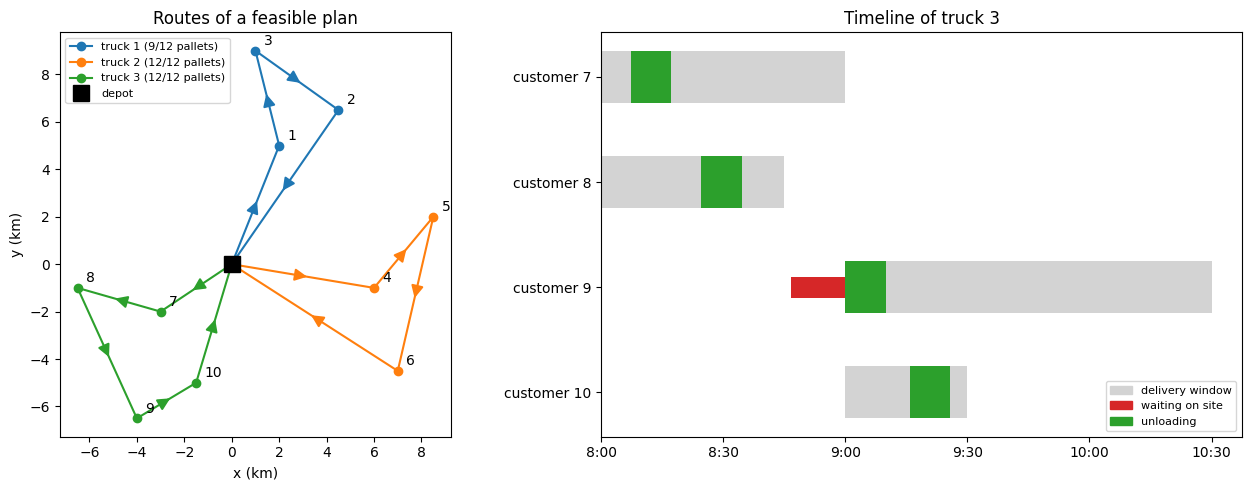

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# Depot (0) and 10 customers: coordinates in km, demand in pallets, window in minutes after 8:00
coords = np.array([[0, 0], [2, 5], [4.5, 6.5], [1, 9], [6, -1], [8.5, 2], [7, -4.5],
                   [-3, -2], [-6.5, -1], [-4, -6.5], [-1.5, -5]])
demand = [0, 3, 4, 2, 5, 3, 4, 2, 3, 4, 3]
window = {7: (0, 60), 8: (0, 45), 9: (60, 150), 10: (60, 90)}
routes = [[1, 3, 2], [4, 5, 6], [7, 8, 9, 10]]
colors = ["tab:blue", "tab:orange", "tab:green"]
SPEED, SERVICE = 0.5, 10  # 30 km/h = 0.5 km/min, 10 min unloading

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})

# Left: routes on the map
for k, route in enumerate(routes):
    path = coords[[0, *route, 0]]
    load = sum(demand[c] for c in route)
    ax1.plot(path[:, 0], path[:, 1], "-o", color=colors[k], label=f"truck {k + 1} ({load}/12 pallets)")
    # Direction arrow in the middle of each leg (depot -> customers -> depot)
    for start, end in zip(path[:-1], path[1:]):
        middle = (start + end) / 2
        step = (end - start) / np.linalg.norm(end - start) * 0.3
        ax1.annotate("", xy=middle + step, xytext=middle - step,
                     arrowprops=dict(arrowstyle="-|>", color=colors[k], lw=1.5, mutation_scale=18))
ax1.plot(0, 0, "ks", ms=12, label="depot")
for i in range(1, 11):
    ax1.annotate(str(i), coords[i], xytext=(6, 4), textcoords="offset points")
ax1.set(title="Routes of a feasible plan", xlabel="x (km)", ylabel="y (km)", aspect="equal")
ax1.legend(loc="upper left", fontsize=8)

# Right: timeline of truck 3 (arrive, wait if early, unload)
clock, prev = 0.0, 0
for row, c in enumerate(routes[2]):
    arrival = clock + np.linalg.norm(coords[c] - coords[prev]) / SPEED
    start = max(arrival, window[c][0])
    a, b = window[c]
    ax2.barh(row, b - a, left=a, color="lightgray", height=0.5)
    if start > arrival:
        ax2.barh(row, start - arrival, left=arrival, color="tab:red", height=0.2)
    ax2.barh(row, SERVICE, left=start, color="tab:green", height=0.5)
    clock, prev = start + SERVICE, c
ax2.set_yticks(range(4), [f"customer {c}" for c in routes[2]])
ax2.set_xticks(range(0, 151, 30), ["8:00", "8:30", "9:00", "9:30", "10:00", "10:30"])
ax2.invert_yaxis()
ax2.set(title="Timeline of truck 3")
ax2.legend(handles=[Patch(color=c, label=l) for c, l in [("lightgray", "delivery window"), ("tab:red", "waiting on site"), ("tab:green", "unloading")]],
           loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# 2. Formal problem statement

Problem version: Level A (Advanced), the Capacitated Vehicle Routing Problem with Time Windows (CVRPTW), with peak-hour traffic.

## 2.1 Problem definition

A fleet of at most $m$ identical vehicles of capacity $Q$ delivers goods from one depot to $n$ customers. Customer $i$ has a demand $q_i$, a service duration $d_i$ and a time window $[a_i,b_i]$ in which service must start. A vehicle that arrives early waits, and late service is forbidden. Travel times depend on the time slot in which the vehicle leaves, so a trip takes longer during the peak. We look for routes that start and end at the depot, serve every customer exactly once, respect the capacity and every time window, and have the smallest total cost. This is the vehicle routing problem of Dantzig and Ramser [1] with the time windows studied by Solomon [4]. Surveys of its formulations and exact methods are in [7, 8].

A solution is a set of routes, the start time $s_i$ of each service, and the total cost $Z$.

Assumptions:

* (A1) There is one depot. The vehicles are identical with capacity $Q$. At most $m$ are used, each on one route, and $m$ is a hard bound.
* (A2) Demands, service durations, time windows and travel times are known and deterministic, and $1\le q_i\le Q$.
* (A3) Each customer is served in one visit by one vehicle. Deliveries are not split.
* (A4) Time windows are hard. Waiting, before and after service, is allowed and costs nothing.
* (A5) Vehicles leave the depot at time $0$ and must be back by the horizon $H$. Leaving at $0$ loses nothing under the objective of 2.4 (see 2.7).
* (A6) The travel time of a trip is fixed by the slot in which the vehicle leaves. Speed changes during a trip are ignored.

## 2.2 Notation and traffic model

The problem lives on a directed graph $G=(V,A)$. The depot appears twice: node $0$ starts every route and node $n+1$ is a copy where every route ends. This lets the depot take part in the time constraints like any other node.

$$N=\{1,\dots,n\},\qquad V=\{0\}\cup N\cup\{n+1\},$$

$$A=\{(0,j):j\in N\}\ \cup\ \{(i,j):i,j\in N,\ i\ne j\}\ \cup\ \{(i,n+1):i\in N\}.$$

There is no arc into $0$, out of $n+1$, or from $0$ to $n+1$, so every route visits at least one customer.

| Symbol | Meaning |
|---|---|
| $n,\ m,\ Q$ | Number of customers, maximum number of vehicles, vehicle capacity |
| $q_i$ | Demand of customer $i$; $q_0=q_{n+1}=0$ |
| $a_i,\ b_i$ | Earliest and latest start of service at $i$. The depot window is $[0,H]$, so $a_{n+1}=0$ and $b_{n+1}=H$ |
| $d_i$ | Service duration at $i$, $d_0=d_{n+1}=0$. Setting $d_i=0$ ignores service times |
| $H$ | End of the planning horizon |
| $P,\ \theta_p$ | Number of traffic slots and their boundaries, $0=\theta_0<\dots<\theta_P=H$ |
| $t_{ij}$ | Free-flow travel time from $i$ to $j$ |
| $\rho_p$ | Congestion factor of slot $p$ ($1$ means free flow) |
| $t_{ij}^p$ | Travel time from $i$ to $j$ when leaving in slot $p$ |
| $c_{ij}$ | Cost of arc $(i,j)$, equal to $t_{ij}$ |

All times share one unit. On benchmark instances $t_{ij}$ is the Euclidean distance, rounded as the benchmark prescribes.

Slot $p$ is the closed interval $[\theta_{p-1},\theta_p]$ and $\mathcal{P}=\{1,\dots,P\}$. The default profile has $P=3$: off-peak on $[0,\theta_1]$, peak on $[\theta_1,\theta_2]$, off-peak on $[\theta_2,H]$, with $\rho_1=\rho_3=1$, $\rho_2=\rho\ge1$ (default $1.5$) and $t_{ij}^p=\rho_p\,t_{ij}$. Any other values of $t_{ij}^p$ can replace this simple peak. Piecewise constant travel times of this kind follow Malandraki and Daskin [11], and a review of time-dependent routing is in [13]. A departure exactly at a slot boundary may use either neighbouring slot, and the faster one is taken.

Setting $\rho=1$ gives the static CVRPTW. Setting in addition $a_i=0$, $b_i=H$ with $H$ large and $d_i=0$ gives the plain CVRP, which the vrplib instances require.

## 2.3 Decision variables

| Variable | Type | Meaning |
|---|---|---|
| $x_{ij}$, $(i,j)\in A$ | binary | 1 if a vehicle drives directly from $i$ to $j$ |
| $z_{ij}^p$, $(i,j)\in A$, $p\in\mathcal{P}$ | binary | 1 if arc $(i,j)$ is used and the vehicle leaves $i$ in slot $p$ |
| $s_i$, $i\in N\cup\{n+1\}$ | continuous | Start of service at $i$; for $i=n+1$ it is the return time |
| $\delta_i$, $i\in N$ | continuous | Time at which the vehicle leaves $i$; the departure from the depot is the constant $\delta_0=0$ |
| $u_i$, $i\in N$ | continuous | Cumulative demand delivered on the route up to and including $i$ |

No variable has a vehicle index. The vehicles are identical and each customer is visited once, so one $s_i$, one $\delta_i$ and one $u_i$ per customer are enough. Routes are read from $x$ by following the selected arcs from node $0$ to node $n+1$. Since $x_{ij}=\sum_p z_{ij}^p$, the variables $x$ are a sum of the variables $z$. We keep them because they make the degree and load constraints easier to read.

## 2.4 Objective function

$$\min\ Z=\sum_{(i,j)\in A}c_{ij}\,x_{ij},\qquad c_{ij}=t_{ij}.$$

$Z$ is the total free-flow travel time, which equals distance on the benchmarks. Waiting costs nothing, and the number of vehicles is bounded by $m$ but not penalised. Traffic therefore acts only through the time constraints: it can make a route infeasible, force a wait, or force a different order, while the cost of an arc stays the same. This keeps the results comparable with the static benchmarks and means an earlier schedule is never worse than a later one.

### 2.5 Complete ILP

$$\min\ \sum_{(i,j)\in A} c_{ij}\,x_{ij}$$

subject to

$$\sum_{j:(i,j)\in A} x_{ij}=1 \qquad \forall\, i\in N \tag{1}$$

$$\sum_{i:(i,j)\in A} x_{ij}=1 \qquad \forall\, j\in N \tag{2}$$

$$\sum_{j\in N} x_{0j}\ \le\ m \tag{3}$$

$$u_i-u_j+Q\,x_{ij}\ \le\ Q-q_j \qquad \forall\, i,j\in N,\ i\ne j \tag{4}$$

$$q_i\ \le\ u_i\ \le\ Q \qquad \forall\, i\in N \tag{5}$$

$$\sum_{p\in\mathcal{P}} z_{ij}^p = x_{ij} \qquad \forall\, (i,j)\in A \tag{6}$$

$$\delta_i\ \ge\ s_i+d_i \qquad \forall\, i\in N \tag{7}$$

$$\delta_i\ \ge\ \theta_{p-1}\,z_{ij}^p \qquad \forall\, (i,j)\in A,\ p\in\mathcal{P} \tag{8}$$

$$\delta_i\ \le\ \theta_p+(H-\theta_p)\,(1-z_{ij}^p) \qquad \forall\, (i,j)\in A,\ p\in\mathcal{P} \tag{9}$$

$$\delta_i+t_{ij}^p-s_j\ \le\ M_{ij}^p\,(1-z_{ij}^p) \qquad \forall\, (i,j)\in A,\ p\in\mathcal{P} \tag{10}$$

$$a_i\ \le\ s_i\ \le\ b_i \qquad \forall\, i\in N\cup\{n+1\} \tag{11}$$

$$x_{ij},\,z_{ij}^p\in\{0,1\},\qquad 0\le\delta_i\le H \tag{12}$$

where $\delta_0=0$ and

$$M_{ij}^p=\max\{\,0,\ \hat H_i+t_{ij}^p-a_j\,\},\qquad \hat H_0=0,\quad \hat H_i=H\ \ (i\in N).$$

| Constraint | Meaning |
|---|---|
| (1), (2) | Every customer is left once and entered once, so it is visited exactly once. |
| (3) | At most $m$ vehicles leave the depot. |
| (4) | If $j$ directly follows $i$, then $u_j\ge u_i+q_j$, so the load accumulates along the route. When $x_{ij}=0$ the constraint always holds. It is the load-based form of the Miller, Tucker and Zemlin constraints [2]. |
| (5) | The load after serving $i$ is at least $q_i$ and at most $Q$. |
| (6) | A used arc has exactly one departure slot, and an unused arc has none. |
| (7) | A vehicle cannot leave a customer before finishing service, and it may wait longer. |
| (8), (9) | If $z_{ij}^p=1$, the departure time $\delta_i$ lies in $[\theta_{p-1},\theta_p]$. If $z_{ij}^p=0$ both hold for any $\delta_i\in[0,H]$. |
| (10) | If $z_{ij}^p=1$, then $s_j\ge\delta_i+t_{ij}^p$: service at $j$ starts after the drive of the chosen slot. Being an inequality, it allows waiting before service. |
| (11) | Service starts inside the window. For $i=n+1$ it forces the return by $H$. |
| (12) | Domains of the binary variables and of $\delta$. |

The model has $(n^2+n)(P+1)$ binary variables, about $3n$ continuous variables and $O(n^2P)$ constraints, and none of these counts depends on $m$. With the three-slot profile there are four times as many binaries as in the static model. Because $\delta_0=0$, constraint (8) forces $z_{0j}^p=0$ for $p\ge2$, so an implementation can drop those variables. Strictly the model is a mixed integer program, since $s$, $\delta$ and $u$ are continuous. If all data are integers, including the values $t_{ij}^p$, an earliest schedule has integer times, so these variables can be declared integer without changing the optimum, which gives a pure ILP.

## 2.6 Correctness of the model

Subtours. Constraints (4) and (5) forbid any cycle $C\subseteq N$ with $x_{ij}=1$ on all its arcs. Summing (4) over the arcs of $C$, the terms $u_i-u_j$ cancel around the cycle and we get $Q|C|\le Q|C|-\sum_{j\in C}q_j$. This is impossible because $q_j\ge1$.

Value of $M_{ij}^p$. When $z_{ij}^p=0$, the left side of (10) is at most $\hat H_i+t_{ij}^p-a_j$, because $\delta_i\le\hat H_i$ and $s_j\ge a_j$, and this bound is reached. So $M_{ij}^p$ is the smallest constant that keeps (10) valid. We compute it for each arc and slot, since a single global $M$ weakens the LP relaxation and can cause numerical trouble. Because vehicles may wait, $\delta_i$ can be as large as $H$, which makes $M_{ij}^p$ larger than in the static model. This is the main reason the traffic model is harder for a solver.

Equivalence with the evaluation rule. A vector satisfying (1) to (12) has its arcs with $x_{ij}=1$ forming at most $m$ routes that partition $N$, and each route is feasible under the rule of 2.6. Along a path, (4) and (5) bound the load by $Q$. For a used arc, (6) gives one slot $p$, (8) and (9) put $\delta_i$ in that slot, (7) gives $\delta_i\ge s_i+d_i$, and (10) gives $s_j\ge\delta_i+t_{ij}^p$. Together with (11) this is a schedule that respects the windows and the horizon, and the rule gives start times no later than any such schedule.

Conversely, take a route that is feasible under the rule. For each arc choose the slot $p$ that attains the minimum, and set $z_{ij}^p=1$, $\delta_i=\max(r_i,\theta_{p-1})$, $s_j$ as in the rule, and $u_i$ equal to the cumulative load. All constraints hold on used arcs by construction. On unused arcs (8), (9) and (10) hold because $z=0$ and by the choice of $M_{ij}^p$, and (4) reduces to $u_i-u_j\le Q-q_j$, which follows from $u_i\le Q$ and $u_j\ge q_j$.

The rule gives the earliest start times because $r\mapsto\text{arr}_{ij}(r)$ is nondecreasing. Each term of the minimum is nondecreasing in $r$, and the set of admissible slots can only shrink as $r$ grows. So a vehicle that is ready earlier never arrives later, which also justifies the departure at time $0$ in (A5).

## 2.7 Modelling choice

We use a two-index formulation. The vehicles are identical, so a vehicle index $k$ adds nothing. A three-index model $x_{ijk}$ would need about $n^2m$ binaries (times $P$ with traffic) and would contain up to $m!$ equivalent copies of each solution, which slows branch and bound. The load constraints (4) are compact but give a weak LP bound. The set partitioning formulation, with one binary per feasible route and solved by column generation, has a much stronger bound and underlies the best exact methods [5, 8]. With traffic, route feasibility would be checked by the rule of 2.6 when a column is generated. We cite it for bounds and do not implement it.

### References Section 2

1. Dantzig, G. B. and Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80-91.
2. Miller, C. E., Tucker, A. W. and Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326-329.
4. Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
5. Cordeau, J.-F., Desaulniers, G., Desrosiers, J., Solomon, M. M. and Soumis, F. (2002). VRP with time windows. In Toth, P. and Vigo, D. (eds), *The Vehicle Routing Problem*, SIAM, 157-193. https://doi.org/10.1137/1.9780898718515.ch7 (accessed 18 October 2026).
6. Pan, B., Zhang, Z. and Lim, A. (2021). A hybrid algorithm for time-dependent vehicle routing problem with time windows. *Computers & Operations Research*, 128, 105193. https://doi.org/10.1016/j.cor.2020.105193 (accessed 21 October 2026).

# **3. Data Representation**

### **3.1 Structure of the available data**

The repository that was provided to us provides files with instances. They're located in the folder "test" and contain what we call "parsed data". By parsed data we mean raw text from an instance (our files) that will then be converted into structured Python dictionaries with the library vrplib. There are mainly 2 formats used to represent our instances :

The standard format for Capacitated Vehicle Routing Problem (CVRP) is **VRPLIB**. Those type of files have the extension ".vrp" and contain the problem specifications and its data. The specifications are key-value pairs separated by a colon and data are value like arrays : the coordinates of the customer and the service times for example.

Here since we chosed the advanced version of the problem we'll focus on the files that use the **"Solomon"** format. The difference with the VRPLIB format is that this one involves a time window and they have the extension ".txt"

Here's an example of what the heading of a Solomon instance can look like:

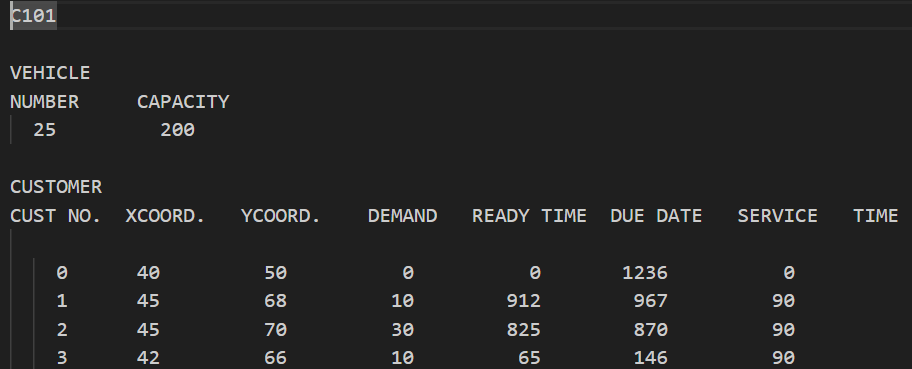

We can see here that the name of the instance is "C101", then we have the informations concerning the vehicles : the number and the capacity of each vehicle.

This instance contains : 100 customers (since we have a hundred rows), 1 depot, a maximum of 25 vehicles that have each a capacity of $Q = 200$. For each row (so customer) we have :
- The **customer number** that represents each node
- The **coordinates** that represent the location of each node ; we have XCOORD and YCOORD (coordonnées de x et y)
- The **demand** (noted $q_i$) which represents the quantity that has to be delivered to a customer that we will represent as i
- The **ready time** (noted $a_i$) that is the earliest permitted start of service
- The **due date** (noted $b_i$)that represents the latest permitted start of service
- The **service time** (noted $d_i$) which is then the duration of service at the customer


By default our depot is at the node (0) so it's located at (40;50). For that row we have no demand, so no ready time and no service duration. But the duration is 1236 meaning that the end of the depot's time window is 1236.

As precised earlier the input data is stored in a table where each row represents a node For the coodinates we have 2 values per node (x and y) and one value for the due date, the ready time and the service time.

With this format the edge weights are computed automatically using Euclidean distances.

### **3.2 Mathematical modelization of the data**

Here the problem is modelled as a directed graph that we name $G = (V,A)$ with V the set of nodes and A the set of permitted directed arcs. An arc $(i,j)$ represents a possibilty of movement between a node i and a node j.

Here are the input parameters of our model :

| Parameter | Description |
|---|---|
| $n$ | Number of customers |
| $m$ | Maximum number of vehicles |
| $Q$ | Vehicle capacity|
| $q_i$ | Demande of the customer i  |
| $(a_i,b_i)$|Earliest and latest permitted servoce start at node i |
|$d_i$ | Service duration at the node i |
|$H$ | End of the planning horizon; depot window is $[0,H]$|
| $t_{ij}$ | Travel time from $i$ to $j$ when departing in slot p |
| $c_{ij}$ | Cost of arc $(i,j)$, $c_{ij}=t_{ij}$ |

Then we have the decision variables that describe the routes that can be taken and their timing :

|Parameter| Description
|---|---|
|$x_{ij}\in{0,1}$| equals 1 if a vehicle travels directly from node (i) to node (j)|
|$z_{ij}^{p}\in{0,1}$| equals 1 if arc (i,j) is used and the vehicle departs from (i) during time slot (p)|
|$s_i$| represents the start-of-service time at node (i)|
|$\delta_i$ |represents the departure time from node (i)|
|$u_i$| represents the cumulative demand delivered along the route up to and including node (i)|

####**Expected outpout**
Our algorithm is expected to produce a list of routes starting at node 0, visiting a sequence of customers and ending at node n+1.
So the solution should include : the selected routes, their total cost and the sufficient timing information to verify the feasibility.

### **3.3. Example of representation**

Let's use the files related to the instance C101.

First, we will read the file using the library

In [ ]:
import vrplib
import numpy as np
import matplotlib.pyplot as plt

# These variables store the data as dictionnaries
# The variable where we will store the parsed data from the file C101.txt
instance = vrplib.read_instance("C101.txt",instance_format="solomon")
# The variable where we will store the data from the proposed solution in C101.sol
solution = vrplib.read_solution("C101.sol")

# We will print the data just to check if we have collected them all
print("Instance:", instance["name"])
print("Available vehicles:", instance["vehicles"])
print("Vehicle capacity:", instance["capacity"])
print("Number of nodes in the original instance:",
      len(instance["demand"]))
print("Number of reference routes:", len(solution["routes"]))
print("Reference solution cost:", solution["cost"])

Now let's construct the nodes and arcs

In [ ]:
n = len(instance["demand"]) - 1

N = list(range(1, n + 1))
end_depot = n + 1

V = [0] + N + [end_depot]

A = (
    [(0, j) for j in N]
    + [(i, j) for i in N for j in N if i != j]
    + [(i, end_depot) for i in N]
)

print("Number of customers:", len(N))
print("Number of model nodes:", len(V))
print("Number of permitted arcs:", len(A))
print("Example arcs:", A[:10])

To plote the instances :

In [ ]:
coordinates = instance["node_coord"]

plt.figure(figsize=(8, 6))

plt.scatter(
    coordinates[1:, 0],
    coordinates[1:, 1],
    label="Customers"
)

plt.scatter(
    coordinates[0, 0],
    coordinates[0, 1],
    marker="s",
    s=100,
    label="Depot"
)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("C101: customer and depot locations")
plt.legend()
plt.grid(True)
plt.show()

Here we displayed the geographical distribution of the customers and the depot. The point of this representation is to focus on the node locations since it would make the figure more difficult to read if we represent every possible arc and the code only represents the permitted movements more precisely.

If we want to represent the matrix
According to the library's convention $D=[d_{ij}]$ where $d_{ij}$ is the Euclidian distance between the nodes $i$ and $j$.
The original matrix dimension is $101\times101$ but to match our mathematical model we have to copy the depot as the node (since we count the return). So our we will have a $102\times102$ matrix.

So let's represent the matrix here :

In [ ]:
D = instance["edge_weight"]

# We added 2 to duplicate the original depot row and column
D_model = np.zeros((n + 2, n + 2))

D_model[:n + 1, :n + 1] = D
D_model[n + 1, :n + 1] = D[0, :]
D_model[:n + 1, n + 1] = D[:, 0]
D_model[n + 1, n + 1] = 0

print("Original matrix dimensions:", D.shape)
print("Model matrix dimensions:", D_model.shape)

# We'll display just 6 rows of the matrix for it to be more readable here :
print("First six rows and columns of the model matrix:")
print(np.round(D_model[:6, :6], 2))

###3.4 Time-dependant matrices



Since we have $P$ time solts with boundaries $\theta_p$ and congestion factors $\rho_p$. The travel time on the arc $(i,j)$ when departing in the time slot $p$ is : $t_{ij}^{p}=\rho_p t_{ij}$

Since our instance here does not provide the traffic parameters for demonstration purposes we will use three times slots and congestion factors that we choose : 1.0, 1.5 and 1.0.

We will use a distance matrix as an assumption just to illustrate :

In [ ]:
H = int(instance["time_window"][0, 1])

P = 3
theta = np.linspace(0, H, P + 1)
rho = np.array([1.0, 1.5, 1.0])

# Illustrative assumption: distance is used as free-flow time
T = D_model.copy()

T_p = [rho[p] * T for p in range(P)]

print("Time-slot boundaries:", theta)
print("Congestion factors:", rho)
print("Number of time-dependent matrices:", len(T_p))
print("Dimensions of each matrix:", T_p[0].shape)

# 4. Theoretical Study of the Problem

**Problem studied:** the Capacitated Vehicle Routing Problem with Time Windows (CVRPTW).

## 4.0 Introduction: what this part requires

The goal of this part is to carry out the theoretical study of the problem. We are asked to:

1. **Identify the complexity class** of the problem (P, NP-complete, NP-hard, ...);
2. **Justify** this classification with
   - a **complexity proof** (reduction to a known problem),
   - **scientific references** (research papers and books);
3. **Explain the implications** of this complexity for potential solving methods, without detailing the methods yet.

**Our approach.** The CVRPTW is built by adding constraints on top of simpler routing problems. We therefore follow a *chain of generalisation*:

$$\text{HC} \;\le_p\; \text{TSP} \;\le_p\; \text{VRP (CVRP)} \;\le_p\; \text{CVRPTW}.$$

- The full scientific approach (membership in NP, reduction, correctness, complexity) is carried out **in detail for the TSP only**, starting from the Hamiltonian Cycle problem, which is known to be NP-complete (Karp, 1972).
- We then pass to the **decision version of the VRP**, and finally to the **CVRPTW**, by using the constraints that are added at each step (vehicles and capacity, then time windows). Each new problem **contains the previous one as a special case**, so it is at least as hard.

## 4.1 The method: how to prove that a problem $\Pi$ is NP-complete

The recipe is always the same six steps.

1. **$\Pi \in NP$.** Describe a certificate (a proposed solution), describe the verification algorithm, and show that both are polynomial.
2. **Choose a known NP-complete problem $\Pi_0$** (similar to $\Pi$: cycles, routes, ...). The direction matters: we reduce $\Pi_0 \le_p \Pi$, the *known* problem to the *new* one.
3. **Describe the transformation $f$**: from any instance $I_0$ of $\Pi_0$, build an instance $f(I_0)$ of $\Pi$.
4. **Show that $f$ runs in polynomial time** (hence the output has polynomial size).
5. **Show the equivalence** $I_0$ is a "yes"-instance $\iff f(I_0)$ is a "yes"-instance. Both directions are needed ("yes" $\to$ "yes" and "no" $\to$ "no", the latter usually through the contrapositive).
6. **Conclude:** $\Pi_0 \le_p \Pi$ so $\Pi$ is NP-hard; with step 1, $\Pi$ is NP-complete.

**Definitions used.**

- A *decision problem* has a yes/no answer for every instance. Optimisation problems ("find the shortest tour") become decision problems by adding a bound $k$ ("is there a tour of length $\le k$?").
- **NP**: decision problems whose "yes"-instances have a certificate of polynomial size that can be verified in polynomial time.
- $A \le_p B$: there is a polynomial-time algorithm $f$ such that $I$ is a "yes"-instance of $A$ $\iff$ $f(I)$ is a "yes"-instance of $B$. Meaning: $B$ is at least as hard as $A$.
- **NP-hard**: every problem of NP reduces to it. **NP-complete**: NP-hard and in NP.

**Typical mistakes to avoid:** reducing in the wrong direction; forgetting membership in NP; proving only one implication; a transformation that is not polynomial; confusing path/cycle, "at least once"/"exactly once", $|V|$ / $|V|-1$.

## 4.2 The Travelling Salesman Problem is NP-complete

### 4.2.1 Decision version of the TSP

- **Data:** a complete weighted graph $G=(V,E)$ with positive integer weights, and an integer $K$.
- **Question:** is there a closed route that passes **at least once** through every vertex, with total weight $\le K$?

Notation: $n=|V|$; $\overline{G}$ is the complement of $G$ (same vertices, an edge exists in $\overline{G}$ iff it does not exist in $G$).

The known problem used for the reduction is **Hamiltonian Cycle (HC)**: given a graph $G$.

### 4.2.2 Part 1: TSP is in NP

Suppose we are given a proposed solution: a sequence of vertices $(w_0, w_1, \dots, w_m = w_0)$. It suffices to check three things:

1. **It is a closed route.** Look at each pair of consecutive vertices and check that they are linked (always true here, since the graph is complete) and that the sequence returns to its starting vertex. This costs $O(m)$.
2. **Every vertex is visited at least once.** Traverse the sequence and tick the vertices seen in a `visited` array. This costs $O(m)$.
3. **The total cost is $\le K$.** Add the weights of the edges used and compare with $K$. This costs $O(m)$.

**Assumption on data access.** We assume that reading the weight of an edge costs $O(1)$ (adjacency matrix). With adjacency lists, one edge test would cost $O(n)$ and the total would be $O(n^2)$, which is still polynomial. The conclusion does not change.

**The certificate has polynomial size.** Since the route may pass several times through the same vertex, we must make sure that a "yes"-instance always has a *short* certificate. Take any valid route and let $x_1,\dots,x_n$ be the vertices in the order of their first visit. Replace the part of the route between $x_i$ and $x_{i+1}$ (and the final part back to $x_1$) by a shortest path between these two vertices. The weight cannot increase, and each shortest path has at most $n-1$ edges. Hence there is always a valid route with at most $n(n-1)$ edges, so the certificate has polynomial size.

**Conclusion:** everything is polynomial (even linear in the length of the route), therefore $\text{TSP} \in NP$. $\square$

### 4.2.3 Part 2: TSP is NP-hard

We want to show $\text{HC} \le_p \text{TSP}$: we transform an instance of HC into an instance of TSP **while keeping the same answer** (yes $\to$ yes, no $\to$ no).

**The transformation.** Start from an arbitrary graph $G=(V,E)$ (not necessarily complete). TSP needs a complete graph, so:

- the edges that exist in $G$ receive weight **1** (they are "good" edges);
- the edges that do not exist in $G$ (the edges of the complement $\overline{G}$) are **added with weight 2** (they are "penalised" edges);
- we choose the bound $K = |V|$ (the number of vertices).

Formally, $G' = (V, E \cup \overline{E})$ with
$$w(x,y)=\begin{cases}1 & \text{if } \{x,y\}\in E,\\ 2 & \text{if } \{x,y\}\in \overline{E},\end{cases}\qquad K=|V|.$$

The following example shows $G$ (5 vertices) and the TSP instance built from it. Solid blue edges have weight 1 (edges of $G$), dashed red edges have weight 2 (added edges).

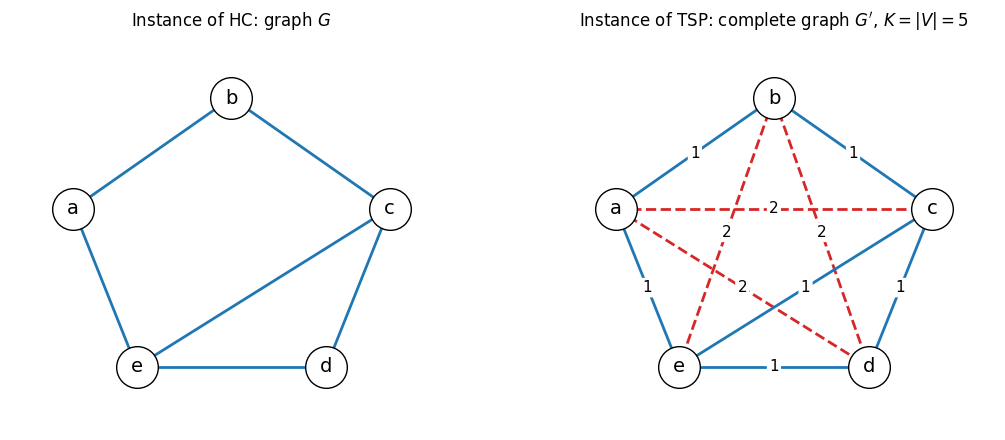

In [ ]:
import matplotlib.pyplot as plt
import itertools

pos = {'a': (0.0, 1.0), 'b': (1.0, 1.7), 'c': (2.0, 1.0), 'd': (1.6, 0.0), 'e': (0.4, 0.0)}
E = {frozenset(p) for p in [('a','b'), ('b','c'), ('c','d'), ('d','e'), ('a','e'), ('c','e')]}
V = list(pos)

def draw_nodes(ax):
    for v, (x, y) in pos.items():
        ax.scatter([x], [y], s=900, facecolor='white', edgecolor='black', zorder=3)
        ax.text(x, y, v, ha='center', va='center', fontsize=14, zorder=4)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_xlim(-0.4, 2.4); ax.set_ylim(-0.4, 2.1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: the original graph G
ax = axes[0]
for e in E:
    u, v = tuple(e)
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color='tab:blue', lw=2, zorder=1)
draw_nodes(ax)
ax.set_title('Instance of HC: graph $G$')

# Right: the complete TSP graph G'
ax = axes[1]
for u, v in itertools.combinations(V, 2):
    inG = frozenset((u, v)) in E
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
            color='tab:blue' if inG else 'tab:red', lw=2, ls='-' if inG else '--', zorder=1)
    mx, my = (pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2
    ax.text(mx, my, '1' if inG else '2', fontsize=11, ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'), zorder=2)
draw_nodes(ax)
ax.set_title("Instance of TSP: complete graph $G'$, $K=|V|=5$")
plt.tight_layout(); plt.show()

**Polynomial time.** One weight is computed for each of the $n(n-1)/2$ pairs of vertices, so the transformation runs in $O(|V|^2)$, which is polynomial.

**Correctness.** We prove: $G$ has a Hamiltonian cycle $\iff$ the TSP instance answers **yes**.

#### What does "the TSP answers yes" mean?

The decision version of the TSP is a yes/no question: *is there a route visiting every vertex with total cost $\le K$?*

- **yes**: such a route exists;
- **no**: no route respects the budget $K$.

In our construction $K=n$, so "the TSP answers yes" means: *there exists a route visiting all vertices of total cost $\le n$*. A reduction must preserve the answer, so we must prove an **equivalence** between "$G$ has a Hamiltonian cycle" and "the TSP instance answers yes". This is exactly what the two directions below do.

**Direction 1 ($\Rightarrow$): if $G$ has a Hamiltonian cycle, then the TSP answers yes.**
A Hamiltonian cycle uses exactly $n$ edges, all of them in $G$, hence all of weight 1. Its total cost is $n \le K=n$. The TSP therefore finds a valid route: it answers **yes**.

**Direction 2 ($\Leftarrow$): if the TSP answers yes, then $G$ has a Hamiltonian cycle.**
Suppose there is a closed route $R$ visiting all vertices with cost $\le n$, and let $m$ be its number of edges.

- To visit $n$ vertices and come back to the start, $R$ needs at least $n$ edges: $m\ge n$.
- Every edge costs at least 1, so $\text{cost}(R)\ge m\ge n$.
- Since $\text{cost}(R)\le n$, we get $m=n$ **and** every edge has weight exactly 1.

Then $R$ has exactly $n$ edges and visits $n$ different vertices, so it visits **each vertex exactly once**. All its edges have weight 1, so they are edges of $G$ (no added edge was used). Hence $R$ is a Hamiltonian cycle of $G$.

**Why weight 2?** The added edges are "penalised": if the route used even **one** of them, its cost would exceed $n$ and the TSP would answer **no**. So the TSP answers yes only if we can make the tour without leaving the edges of $G$.

**Careful about the bound:** a Hamiltonian cycle has as many edges as vertices, so $K=|V|$ (not $|V|-1$, which would be the case for a path).

**Conclusion.** $\text{HC}\le_p\text{TSP}$, so TSP is NP-hard (HC is NP-complete). Together with Part 1, **TSP is NP-complete**.

## 4.3 The VRP (CVRP) is NP-hard

### Decision version of the CVRP

- **Data:** a complete weighted graph with a special vertex, the **depot** $d$; customers $V\setminus\{d\}$ with demands $q_i$; $m$ vehicles of capacity $Q$; a bound $k$.
- **Question:** are there at most $m$ routes, each starting and ending at the depot, such that every customer is served by exactly one route, the total demand of each route is $\le Q$, and the total weight of all routes is $\le k$?

### In NP

The certificate is the list of routes. We check in polynomial time that each route starts and ends at the depot, that every customer appears exactly once overall, that each route respects the capacity $Q$, that there are at most $m$ routes, and that the total weight is $\le k$.

### NP-hardness: $\text{TSP}\le_p\text{VRP}$

The VRP is a TSP to which we add **vehicles** and a **capacity**. Given a TSP instance $(G,k)$:

- choose any vertex of $G$ as the **depot** $d$; all other vertices become **customers** with demand $q_i=1$;
- use **one single vehicle** ($m=1$) with capacity $Q \ge$ number of customers, e.g. $Q=|V|-1$, so the capacity **never constrains** the solution;
- keep the same graph and the same bound $k$.

**Polynomial time:** the graph is copied and $O(|V|)$ numbers are added.

**Equivalence.** With one vehicle and a non-binding capacity, a feasible VRP solution is a single closed route through the depot and all the customers, i.e. a TSP tour of the same weight; conversely, a TSP tour starting at $d$ is a feasible VRP solution.

**Remark ("at least once" vs "exactly once").** The TSP allows several passages through a vertex, whereas the VRP serves each customer exactly once. This is harmless for the instances produced by the reduction from HC: their weights (1 and 2) satisfy the **triangle inequality**, so a route that revisits a vertex can always be shortcut without increasing its weight.

**Conclusion.** $\text{TSP}\le_p\text{VRP}$ and $\text{VRP}\in NP$, so the VRP (CVRP) is NP-complete (in particular NP-hard).

## 4.4 The CVRPTW is NP-hard

### Decision version of the CVRPTW

It is the decision CVRP above, with in addition, for each customer $i$:

- a **time window** $[e_i, l_i]$ during which the service must start (arriving early means waiting, arriving late is forbidden);
- a **service time** $s_i$;
- travel times $t_{ij}$ (here equal to the edge weights).

### In NP

The certificate is the list of routes. In addition to the CVRP checks, we compute along each route the arrival times (cumulating travel times, waiting times and service times) and check that every service starts inside its window. All of this is polynomial.

### NP-hardness: $\text{CVRP}\le_p\text{CVRPTW}$

The CVRPTW is a CVRP to which we add **time windows**. Given a CVRP instance:

- give each customer a **very wide window** $[0, M]$, with $M$ large enough that nobody can ever be late (for instance $M$ = the sum of all edge weights, which is an upper bound on the duration of any route of weight $\le k$);
- set all **service times to 0**;
- keep everything else identical (graph, demands, $m$, $Q$, $k$).

**Polynomial time:** we only add one interval and one zero per customer, plus the computation of $M$ in $O(|V|^2)$.

**Equivalence.** With these windows, the time constraints are **never binding**: no arrival can fall outside $[0,M]$ and no waiting is needed. The feasible solutions of the CVRPTW instance are exactly the feasible solutions of the CVRP instance, with the same cost. Hence yes-instances map to yes-instances and no-instances to no-instances.

### Conclusion of the chain

$$\text{TSP}\;\le_p\;\text{VRP}\;\le_p\;\text{CVRPTW}.$$

Each added constraint (vehicles and capacity, then time windows) **generalises** the previous problem: by making it non-binding, we recover the previous problem. Therefore the CVRPTW is at least as hard as the TSP: it is **NP-hard**. Its decision version belongs to NP (capacities, windows and cost are verified in polynomial time), hence it is **NP-complete**.

Time windows even make the problem harder in practice: Savelsbergh (1985) showed that, for the routing problem with time windows, merely deciding whether a **feasible** solution exists is already NP-complete.

## 4.5 Summary of the classification

| Problem | Reduced from | Key idea of the construction | Result |
|---|---|---|---|
| TSP | Hamiltonian Cycle | complete the graph; weight 1 for edges, 2 for non-edges; $K=|V|$ | NP-complete |
| VRP (CVRP) | TSP | 1 vehicle, capacity large enough, same $k$ | NP-hard (decision version NP-complete) |
| CVRPTW | CVRP | windows $[0,M]$ with $M$ large, service times 0 | NP-hard (decision version NP-complete) |

**Complexity class of our problem: the CVRPTW is NP-hard** (its decision version is NP-complete).

## 4.6 Implications for the solving methods

We only discuss here what the complexity result implies; the methods themselves will be detailed in the next parts.

1. **No polynomial exact algorithm is expected.** Since the CVRPTW is NP-hard, no algorithm solving it optimally in polynomial time is expected to exist, unless $P=NP$.
2. **Exact methods are limited in size.** Exact methods guarantee optimality, but their running time grows exponentially with the number of customers. They are practical only for small to medium-sized instances.
3. **For large instances we must give up the optimality guarantee.** We turn to approximate methods (heuristics and metaheuristics), which produce good solutions in reasonable time but without a guarantee of optimality.
4. **The added constraints make the search harder.** The capacity and time-window constraints make even *finding a feasible solution* difficult, so the chosen method will have to handle feasibility explicitly.
5. **Solution quality must be assessed empirically.** Without an optimality guarantee, solutions are evaluated by comparison with bounds or best-known solutions on benchmark instances (Solomon instances, VRPLIB), for example through the gap to the best known value.

## 4.7 References

1. S. A. Cook. *The complexity of theorem-proving procedures.* Proceedings of the 3rd Annual ACM Symposium on Theory of Computing (STOC), 1971, pp. 151–158. — NP-completeness of SAT.
2. R. M. Karp. *Reducibility among combinatorial problems.* In R. E. Miller and J. W. Thatcher (eds.), *Complexity of Computer Computations*, Plenum Press, 1972, pp. 85–103. — NP-completeness of Hamiltonian Cycle.
3. M. R. Garey and D. S. Johnson. *Computers and Intractability: A Guide to the Theory of NP-Completeness.* W. H. Freeman, 1979. — Framework of NP-completeness; TSP and Hamiltonian Cycle.
4. G. B. Dantzig and J. H. Ramser. *The truck dispatching problem.* Management Science, 6(1), 1959, pp. 80–91. — Origin of the VRP.
5. J. K. Lenstra and A. H. G. Rinnooy Kan. *Complexity of vehicle routing and scheduling problems.* Networks, 11(2), 1981, pp. 221–227. — NP-hardness of the VRP.
6. M. W. P. Savelsbergh. *Local search in routing problems with time windows.* Annals of Operations Research, 4, 1985, pp. 285–305. — Difficulty of time windows (feasibility is already NP-complete).
7. M. M. Solomon. *Algorithms for the vehicle routing and scheduling problems with time window constraints.* Operations Research, 35(2), 1987, pp. 254–265. — Benchmark instances for the VRPTW.
8. P. Toth and D. Vigo (eds.). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM, 2014. — Reference book on the VRP and its variants.

# 6. Solution method

### 6.1 Chosen method and justification

We solve the problem with an adaptive large neighbourhood search (ALNS) [15]. A Clarke-Wright savings solution [14] gives the starting point, a granular local search [17] improves the solutions the loop produces, and a simulated annealing rule [20] decides which candidates are kept.

A heuristic is needed because the problem is NP-hard (Section 4) and the ILP of Section 2 only closes small instances, while the project targets several thousand customers. ALNS fits this problem for four reasons.

* Destroy and repair change many customers in one step, so the search can leave regions that moves of a single customer cannot leave.
* The repair step is an insertion procedure. Under time windows an insertion is tested with the evaluation rule of Section 2.6, and the same test serves construction, repair and local search. The search therefore stays in the feasible space and needs no penalty terms.
* Granular neighbour lists restrict insertions and moves to nearby customers, which keeps the cost of an iteration bounded when $n$ is large.
* Operators are chosen according to their recent results, so we do not have to decide in advance which rule suits an instance.

Pan, Zhang and Lim [18] solve a closely related problem, the time-dependent VRPTW, with a hybrid of ALNS and tabu search. They report that a multi-start tabu variant performs worse than the hybrid, and that a variant restricted to feasible solutions loses little. Their objective and run times differ from ours, so we read this as support for the design and not as a prediction for our instances.

Other methods were considered. Ant colony optimisation needs an $n\times n$ pheromone matrix. Particle swarm optimisation works in a continuous space, while a route is an ordered list. A genetic algorithm stores a population, and crossover easily breaks time windows. Simulated annealing alone has no operator that moves many customers at once, so we use it only as the acceptance rule. Tabu search and hill climbing serve as baselines in the experimental study.

### 6.2 Solutions and feasibility

A solution $S=\{R_1,\dots,R_k\}$ is a set of routes that together visit every customer exactly once. A route $R=(i_1,\dots,i_l)$ is an ordered list of customers, and the vehicle drives $0\to i_1\to\dots\to i_l\to n+1$. We do not store departure times. They are computed from the route with the evaluation rule of Section 2.6: leave as soon as possible, and wait at a customer if the vehicle arrives before the window opens.

The cost of a solution is the total travel cost of its routes:
$$f(S)=\sum_{R\in S}\sum_{h=0}^{l}c_{i_hi_{h+1}},$$
which is the objective $Z$ of Section 2.

A solution is feasible if it uses at most $m$ routes and every route respects three conditions: the total demand is at most $Q$, service at each customer starts within its window $[a_i,b_i]$, and the vehicle is back at the depot by $H$. By Section 2.7, a feasible solution is a feasible solution of the ILP.

During the search we also use partial solutions: feasible routes plus a pool $U$ of customers that are waiting to be reinserted.

### 6.3 Initial solution

*Clarke-Wright savings* [14]. Each customer starts in its own route. For two customers $i$ and $j$ the saving is $\sigma_{ij}=c_{i,n+1}+c_{0j}-c_{ij}$. Savings are computed only between a customer and the members of its neighbour list (6.4) and sorted in decreasing order. Two routes are merged when $i$ ends one route, $j$ starts another, and the merged route is feasible. Routes are never reversed, because time windows fix their direction. The savings use the distances $c_{ij}$ as a static proxy for the time-dependent travel times.

*Fleet bound.* Since $m$ is a hard bound, a savings solution with more than $m$ routes is not admissible. In that case a route elimination step empties the smallest route into the pool $U$ and reinserts its customers with the repair operators of 6.5. If this fails, the run reports that the bound could not be met. This does not prove that the instance is infeasible.

### 6.4 Neighbourhood structure

*Granular neighbour lists.* For each customer $i$, the list $\mathcal{N}_\kappa(i)$ holds the $\kappa$ closest customers that are compatible with $i$ in time. The lists are built once. Every insertion and every local search move connects a customer only with a member of its list, as in the granular tabu search of Toth and Vigo [17]. The number of candidate moves per customer is then $O(\kappa)$ instead of $O(n)$.

*Large neighbourhood.* A neighbour $S'$ of $S$ is obtained in three steps: a destroy operator removes $\nu$ customers into the pool $U$, a repair operator reinserts all of them, and a local search improves the changed routes. The number $\nu$ is bounded so that the cost of one iteration stays limited on large instances.

*Local search neighbourhoods.* Relocate, swap, Or-opt and 2-opt*, all restricted to $\mathcal{N}_\kappa$ and all subject to the feasibility test of 6.2.

### 6.5 Operators

*Destroy operators.* Each maps a solution $S$ and a number $\nu$ to a partial solution $(S',U)$ with $|U|=\nu$.

* Random removal picks customers uniformly. It adds diversity.
* Worst removal favours customers whose removal saves the most distance, $\Delta_i=c_{pi}+c_{iv}-c_{pv}$ for predecessor $p$ and successor $v$. A random element keeps it from choosing the same customers every time.
* Shaw removal [16] removes a customer and then customers related to it, where relatedness combines distance, difference of service start times and difference of demands. The removed group can then be exchanged between routes.

*Repair operators.* Each maps a partial solution $(S',U)$ to a solution. Customer $u$ is inserted between $i$ and $j$ at cost $\Delta_u=c_{iu}+c_{uj}-c_{ij}$, only in feasible positions and only in routes that contain a member of $\mathcal{N}_\kappa(u)$, or in a new route if $k<m$.

* Greedy insertion repeatedly inserts the pool customer with the cheapest feasible position.
* Regret-2 insertion repeatedly inserts the customer with the largest difference between its second-best and best route. A customer with a single feasible route goes first. This protects customers with few options from losing their only slot.

If a customer has no feasible position, the candidate is rejected.

*Local search moves.* Relocate moves one customer to another position. Swap exchanges two customers. Or-opt moves a chain of two or three consecutive customers. 2-opt* exchanges the tails of two routes [19], and each tail keeps its direction. Plain 2-opt is not used, because reversing a segment changes the arrival time at every customer in it and all their windows would have to be rechecked.

### 6.6 Guidance mechanisms

*Adaptive operator selection* [15]. Each destroy and each repair operator has a weight. Operators are drawn by roulette wheel in proportion to their weights. During a segment of iterations, an operator earns a score when it produces a new best solution, an improvement, or an accepted worse solution. At the end of the segment the weights are updated from the average score per use, so the search shifts toward the operators that work on the current instance.

*Acceptance by simulated annealing* [20]. A candidate $S'$ replaces the current solution $S$ if $f(S')<f(S)$, and otherwise with probability $\exp\{-(f(S')-f(S))/T\}$. The temperature $T$ decreases during the run. Early in the run the search accepts small deteriorations and explores, and late in the run it accepts almost only improvements.

*Restart.* After a long period without improvement, the current solution is reset to the best one found.

Local search, greedy and regret insertion, and the low final temperature intensify the search. Random and Shaw removal, the high initial temperature and the adaptive weights diversify it.

### 6.7 Algorithm

The method has three stages. Initialisation builds the neighbour lists and the starting solution. The main loop applies one destroy, repair, local search and acceptance step per iteration. The loop stops at a time limit or after a number of iterations without improvement, and a final local search is applied to the best solution.

```
Algorithm 1: ALNS for the CVRPTW with peak traffic
Input: instance, parameters, random seed
 1  build neighbour lists N_kappa(i)
 2  S <- ClarkeWright()
 3  if k(S) > m: S <- RouteElimination(S)
 4  S_best <- S
 5  while stopping criterion not met:
 6      draw destroy operator d and repair operator r by roulette wheel
 7      (S', U) <- d(S) ; S' <- r(S', U)
 8      if U is not empty: reject, continue
 9      S' <- LocalSearch(S')
10      if f(S') < f(S_best): S_best <- S'
11      S <- S' if accepted by the annealing rule
12      update temperature, scores and weights
13      restart from S_best if no improvement for a long period
14  S_best <- LocalSearch(S_best)
15  return S_best
```

Every returned solution is checked with the evaluation rule of 6.2, so it satisfies the ILP constraints of Section 2. The run is repeated with several random seeds per instance.

### 6.8 Link with the exact model and limitations

On small instances the ILP gives the optimal cost, so the optimality gap of the heuristic can be computed exactly. With one traffic slot, open windows and zero service times the method solves the plain CVRP, which allows comparison with best-known values on vrplib instances.

The method gives no optimality guarantee, and its quality is measured by gaps. It searches only feasible solutions, so regions reachable only through infeasible intermediate solutions are not visited. The neighbour lists mean that a good move between two distant customers is never tried. Travel times are step functions fixed by the departure slot, which can differ from models with speeds that change during a trip [10].

### References cited in Section 6

1. Ichoua, S., Gendreau, M. and Potvin, J.-Y. (2003). Vehicle dispatching with time-dependent travel times. *European Journal of Operational Research*, 144(2), 379-396.
2. Clarke, G. and Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research*, 12(4), 568-581.
3. Ropke, S. and Pisinger, D. (2006). An adaptive large neighborhood search heuristic for the pickup and delivery problem with time windows. *Transportation Science*, 40(4), 455-472.
4. Shaw, P. (1998). Using constraint programming and local search methods to solve vehicle routing problems. *CP98*, LNCS 1520, Springer, 417-431.
5. Toth, P. and Vigo, D. (2003). The granular tabu search and its application to the vehicle-routing problem. *INFORMS Journal on Computing*, 15(4), 333-346.
6. Pan, B., Zhang, Z. and Lim, A. (2020). A hybrid algorithm for time-dependent vehicle routing problem with time windows. Preprint submitted to *Computers & Operations Research*.
7. Potvin, J.-Y. and Rousseau, J.-M. (1995). An exchange heuristic for routeing problems with time windows. *Journal of the Operational Research Society*, 46(12), 1433-1446.
8. Kirkpatrick, S., Gelatt, C. D. and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220(4598), 671-680.